<a href="https://colab.research.google.com/github/labviros/computer-vision-topics/blob/version2020/lesson05-homography/sift_homography.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Implementing DLT - Basic


In [3]:
def my_DLT(pts1,pts2):

  # Add homogeneous coordinates
  #TORNAR em coordenadas homegeneas os pontos
  pts1 = pts1.T
  pts1 = np.vstack((pts1, np.ones(pts1.shape[1])))
  pts2 = pts2.T
  pts2 = np.vstack((pts2, np.ones(pts2.shape[1])))

  numpts = pts1.shape[1]


  # Compute matrix A
  #recbe vetor com 4 pares de pontos difertens e monta a matriz Ai e empilhar as 4 matrizes
  # pi = ponto da primeira imagemm p' = [x',y',w']
  # MATRIZ A:
 # [0     0      0  -w'x  -w'y  -w'w  y'x   y'y   y'w
 # [w'x   w'y   w'w   0    0     0   -x'x  -x'y  -x'w]

  A = np.zeros((2*numpts, 9))

  for i in range (numpts):
    A[2*i,3:6]     = -pts2[2,i]*pts1[:,i]
    A[2*i,6:9]     =  pts2[1,i]*pts1[:,i]

    A[2*i+1,0:3] =   pts2[2,i]*pts1[:,i]
    A[2*i+1,6:9]   =  -pts2[0,i]*pts1[:,i]

  # Perform SVD(A) = U.S.Vt to estimate the homography
  U,S,Vt = np.linalg.svd(A)
  h = Vt[-1,:]


  # Reshape last column of V or last line of Vt as the homography matrix
  H_matrix = h.reshape((3,3))

  return H_matrix

#Rectifying a Document

<Figure size 640x480 with 0 Axes>

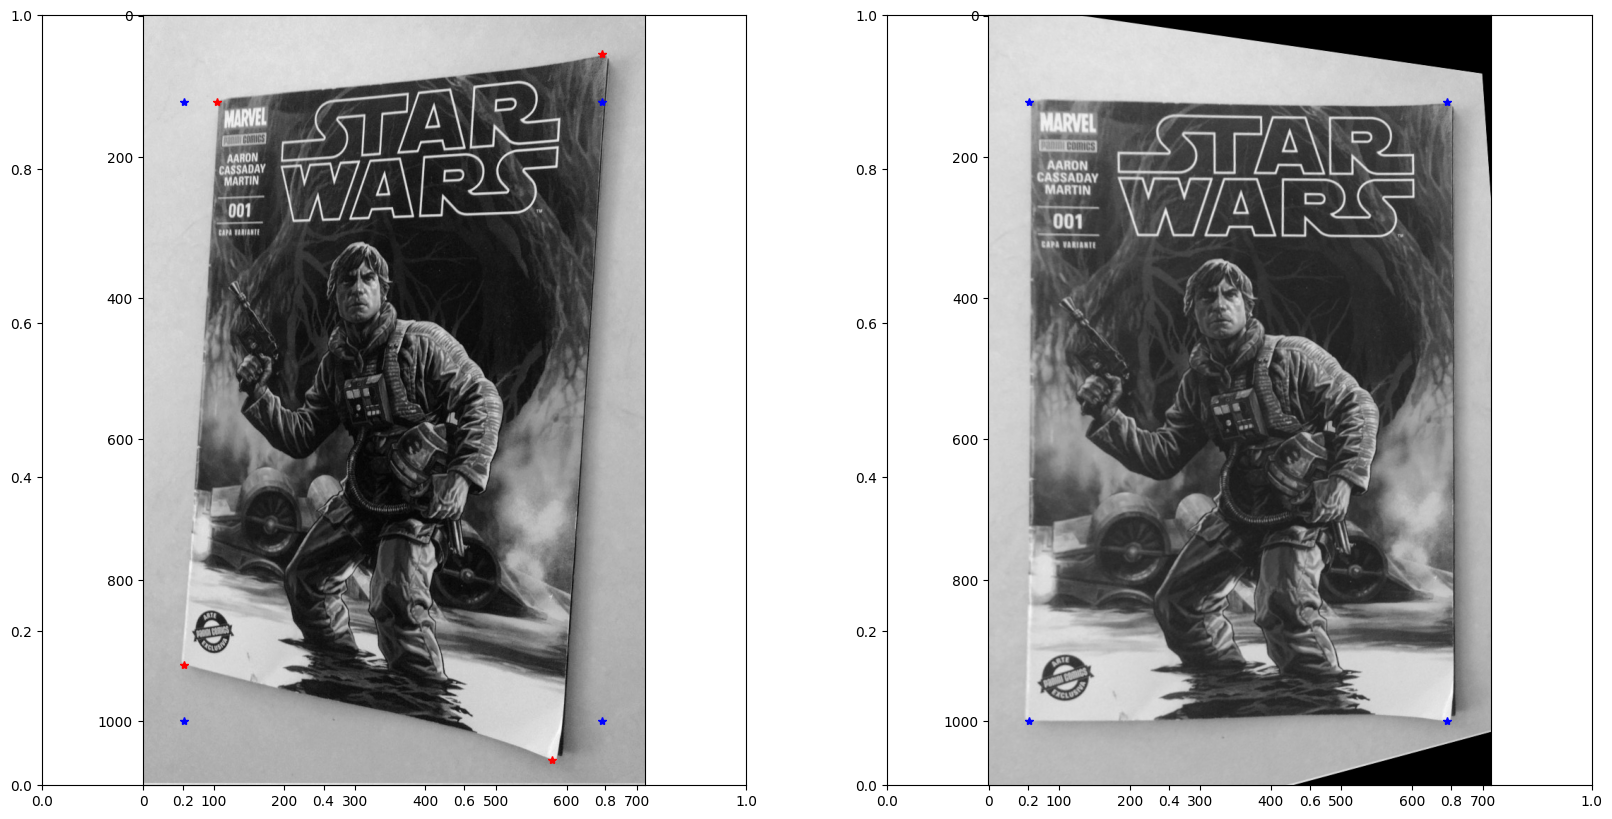

In [4]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
import imutils
#import plotly.express as px
%matplotlib inline

### Setting printing options
np.set_printoptions(formatter={'float': lambda x: "{0:0.3f}".format(x)})
np.set_printoptions(precision=3,suppress=True)


#MIN_MATCH_COUNT = 10
img1 = cv.imread('comicsStarWars02.jpg',0) # queryImage


corners_img1 = np.array([[105,123],[650,55],[580,1055],[58,920]])
corners_img2 = np.array([[58,123],[650,123],[650,1000],[58,1000]])

src_pts = np.float32(corners_img1)
dst_pts = np.float32(corners_img2)



#####################################################
# Substitute OpenCv function for your homography function

# M, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC,5.0)
M = my_DLT(corners_img1, corners_img2)

#####################################################


img2 = cv.warpPerspective(img1, M, (img1.shape[1],img1.shape[0])) #, None) #, flags[, borderMode[, borderValue]]]]	)

fig = plt.figure()
fig, axs = plt.subplots(1,2,figsize=(20,10))
ax1 = fig.add_subplot(1,2,1)
plt.imshow(img1, 'gray')
plt.plot(corners_img2[:,0],corners_img2[:,1],'*b')
plt.plot(corners_img1[:,0],corners_img1[:,1],'*r')
ax2 = fig.add_subplot(1,2,2)
plt.imshow(img2,'gray')
plt.plot(corners_img2[:,0],corners_img2[:,1],'*b')
plt.show()